# Student Performance Analysis
### Data Preparation and Analysis using NumPy, Pandas, Matplotlib, Plotly, EDA and Feature Engineering


## Step 1: Dataset Collection

**Dataset name:** Students Performance in Exams  
**Source URL:** https://www.kaggle.com/datasets/spscientist/students-performance-in-exams  
**Description:** Scores of 1000 students in Math, Reading and Writing, with background information: gender, race/ethnicity group, parental level of education, lunch type and test-preparation course.  
**Format:** CSV, 1000 rows x 8 columns

### Problem statement
Understand which background factors are associated with students' exam performance, and prepare the data for further modelling.

### Objectives
1. Clean and validate the dataset.
2. Explore score distributions and the relationships between variables.
3. Visualise findings with Matplotlib (static) and Plotly (interactive).
4. Engineer meaningful features (encoded and scaled) for machine learning.
5. Summarise findings, recommendations and limitations.

## Step 2: Python and NumPy

NumPy is used for fast numerical work. This section loads the score columns into NumPy arrays, then practises array creation, indexing, slicing, boolean masking, arithmetic and statistics (mean, median, std, min, max, percentiles).

In [11]:
#Connect to mydrive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)
sns.set_theme(style="whitegrid")

SHOW_PLOTS = True            # set to False to only save charts without opening windows/browser tabs

In [13]:
# ---------- folders ----------
BASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
OUTPUT_DIR = BASE_DIR / "outputs"
CHART_DIR = OUTPUT_DIR / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

candidates = [BASE_DIR / "StudentsPerformance.csv", BASE_DIR / "data" / "StudentsPerformance.csv"]
DATA_PATH = next((p for p in candidates if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError("StudentsPerformance.csv not found. Put it next to this script or in a 'data' folder.")
else:
    print(f"Success: Dataset found at {DATA_PATH}")


def save_and_show(name):
    """Save the current Matplotlib figure into outputs/charts and optionally show it."""
    plt.tight_layout()
    plt.savefig(CHART_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    if SHOW_PLOTS:
        plt.show()
    plt.close()


def save_plotly(fig, name):
    """Save a Plotly figure as interactive HTML and optionally show it."""
    fig.write_html(CHART_DIR / f"{name}.html")
    if SHOW_PLOTS:
        fig.show()


def section(title):
    print("\n" + "=" * 80 + f"\n{title}\n" + "=" * 80)


Success: Dataset found at /content/StudentsPerformance.csv


In [14]:
from google.colab import files
import os

uploaded = files.upload()
for filename in uploaded.keys():
    print(f'User uploaded file "{filename}"')
    # If needed, move it to base directory
    if filename == 'StudentsPerformance.csv':
        print("Dataset successfully uploaded and ready for analysis!")

Saving StudentsPerformance.csv to StudentsPerformance (1).csv
User uploaded file "StudentsPerformance (1).csv"


### Load numerical data into NumPy arrays

In [15]:
# ---------- load numerical data into NumPy arrays ----------
section("STEP 2: NUMPY OPERATIONS")
raw = pd.read_csv(DATA_PATH)
math_arr = raw["math score"].to_numpy()
read_arr = raw["reading score"].to_numpy()
write_arr = raw["writing score"].to_numpy()
scores = raw[["math score", "reading score", "writing score"]].to_numpy(dtype=float)   # 2-D array (1000 x 3)


STEP 2: NUMPY OPERATIONS


### Array creation

In [16]:
# Array creation
print("Array shape (students x subjects):", scores.shape, "| dtype:", scores.dtype)
zeros = np.zeros((2, 3)); ones = np.ones((2, 3))
seq = np.arange(0, 101, 10)               # 0,10,...,100
lin = np.linspace(0, 1, 5)
print("arange :", seq)
print("linspace:", lin)
print("zeros / ones:\n", zeros, "\n", ones)

Array shape (students x subjects): (1000, 3) | dtype: float64
arange : [  0  10  20  30  40  50  60  70  80  90 100]
linspace: [0.   0.25 0.5  0.75 1.  ]
zeros / ones:
 [[0. 0. 0.]
 [0. 0. 0.]] 
 [[1. 1. 1.]
 [1. 1. 1.]]


### Indexing and slicing

In [17]:
# Indexing and slicing
print("\nFirst student's scores           :", scores[0])
print("Math score of 5th student        :", scores[4, 0])
print("First 5 math scores              :", math_arr[:5])
print("Last 5 writing scores            :", write_arr[-5:])
print("Rows 10-14, all subjects:\n", scores[10:15, :])
print("Every 100th student's math score :", math_arr[::100])


First student's scores           : [72. 72. 74.]
Math score of 5th student        : 76.0
First 5 math scores              : [72 69 90 47 76]
Last 5 writing scores            : [95 55 65 77 86]
Rows 10-14, all subjects:
 [[58. 54. 52.]
 [40. 52. 43.]
 [65. 81. 73.]
 [78. 72. 70.]
 [50. 53. 58.]]
Every 100th student's math score : [72 79 67 81 59 74 54 79 67 85]


### Boolean masking

In [18]:
# Boolean masking
print("\nStudents with math score > 90    :", (math_arr > 90).sum())
print("Students with any score below 30 :", (scores < 30).any(axis=1).sum())
print("Math scores of top performers    :", math_arr[math_arr >= 95][:10])


Students with math score > 90    : 50
Students with any score below 30 : 18
Math scores of top performers    : [ 97  98  99 100  96  97  99  97  99 100]


### Arithmetic operations

In [19]:
# Arithmetic operations
total_np = math_arr + read_arr + write_arr          # element-wise addition
average_np = total_np / 3                            # element-wise division
weighted_np = 0.4 * math_arr + 0.3 * read_arr + 0.3 * write_arr
diff_np = write_arr - read_arr
print("\nFirst 5 totals   :", total_np[:5])
print("First 5 averages :", np.round(average_np[:5], 2))
print("First 5 weighted :", np.round(weighted_np[:5], 2))
print("Scores as +5 bonus (capped at 100), first 5 math:", np.minimum(math_arr[:5] + 5, 100))


First 5 totals   : [218 247 278 148 229]
First 5 averages : [72.67 82.33 92.67 49.33 76.33]
First 5 weighted : [72.6 81.  92.4 49.1 76.3]
Scores as +5 bonus (capped at 100), first 5 math: [77 74 95 52 81]


### Descriptive statistics

In [20]:
# Descriptive statistics
print("\n{:<10}{:>8}{:>8}{:>8}{:>6}{:>6}{:>8}{:>8}{:>8}".format(
    "Subject", "Mean", "Median", "Std", "Min", "Max", "P25", "P50", "P75"))
for name, arr in [("Math", math_arr), ("Reading", read_arr), ("Writing", write_arr)]:
    p25, p50, p75 = np.percentile(arr, [25, 50, 75])
    print("{:<10}{:>8.2f}{:>8.1f}{:>8.2f}{:>6}{:>6}{:>8.1f}{:>8.1f}{:>8.1f}".format(
        name, arr.mean(), np.median(arr), arr.std(), arr.min(), arr.max(), p25, p50, p75))
print("P10 / P90 of math score :", np.percentile(math_arr, [10, 90]))
print("Column means (axis=0)   :", scores.mean(axis=0).round(2))
print("Correlation matrix (np.corrcoef):\n", np.corrcoef(scores.T).round(3))


Subject       Mean  Median     Std   Min   Max     P25     P50     P75
Math         66.09    66.0   15.16     0   100    57.0    66.0    77.0
Reading      69.17    70.0   14.59    17   100    59.0    70.0    79.0
Writing      68.05    69.0   15.19    10   100    57.8    69.0    79.0
P10 / P90 of math score : [47. 86.]
Column means (axis=0)   : [66.09 69.17 68.05]
Correlation matrix (np.corrcoef):
 [[1.    0.818 0.803]
 [0.818 1.    0.955]
 [0.803 0.955 1.   ]]


## Step 3: Pandas Operations

Load the CSV into a Pandas DataFrame and inspect it: first/last five rows, shape, column names, data types, summary statistics, missing values and duplicates.

In [21]:
section("STEP 3: PANDAS OPERATIONS")
df_raw = pd.read_csv(DATA_PATH)           # untouched copy, used later for before/after comparison
df = df_raw.copy()

print("First 5 records:");  print(df.head())
print("\nLast 5 records:"); print(df.tail())
print(f"\nNumber of rows: {df.shape[0]} | Number of columns: {df.shape[1]}")
print("\nColumn names:", df.columns.tolist())
print("\nData types:"); print(df.dtypes)
print("\nDataFrame info:"); df.info()
print("\nSummary statistics (numerical):"); print(df.describe().T)
print("\nSummary statistics (categorical):"); print(df.describe(include="object").T)
print("\nMissing values per column:"); print(df.isna().sum())
print("\nDuplicate records:", df.duplicated().sum())


STEP 3: PANDAS OPERATIONS
First 5 records:
   gender race/ethnicity parental level of education         lunch test preparation course  math score  reading score  writing score
0  female        group B           bachelor's degree      standard                    none          72             72             74
1  female        group C                some college      standard               completed          69             90             88
2  female        group B             master's degree      standard                    none          90             95             93
3    male        group A          associate's degree  free/reduced                    none          47             57             44
4    male        group C                some college      standard                    none          76             78             75

Last 5 records:
     gender race/ethnicity parental level of education         lunch test preparation course  math score  reading score  writing score
995  f

## Step 4: Data Cleaning and Preprocessing

Clean and prepare the data: standardise column names and data types, validate score ranges, handle missing values and duplicates, detect and analyse outliers (IQR rule), and compare the data before and after cleaning.

> The raw dataset has no missing values or duplicates, so those steps change nothing; the code is still included and documents the check.

In [22]:
section("STEP 4: DATA CLEANING AND PREPROCESSING")


STEP 4: DATA CLEANING AND PREPROCESSING


### 4.3 Correct inconsistent column names

In [23]:
# 4.3 Correct inconsistent column names (lower-case, underscores instead of spaces and '/')
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
print("Cleaned column names:", df.columns.tolist())

score_cols = ["math_score", "reading_score", "writing_score"]
cat_cols = ["gender", "race_ethnicity", "parental_level_of_education", "lunch", "test_preparation_course"]

Cleaned column names: ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score']


### 4.3 Correct data types / inconsistent text

In [24]:
# 4.3 Correct data types / inconsistent text
for c in cat_cols:
    df[c] = df[c].astype(str).str.strip().str.lower()
    df[c] = df[c].astype("category")
for c in score_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

### 4.1 Missing values

In [25]:
# 4.1 Missing values: scores outside 0-100 are invalid -> NaN, then impute
for c in score_cols:
    df.loc[~df[c].between(0, 100), c] = np.nan
print("\nMissing values after validation:\n", df.isna().sum())
for c in score_cols:                                   # numeric -> median
    df[c] = df[c].fillna(df[c].median())
for c in cat_cols:                                     # categorical -> mode
    if df[c].isna().any():
        df[c] = df[c].fillna(df[c].mode()[0])
print("Total missing values after imputation:", int(df.isna().sum().sum()))
for c in score_cols:
    df[c] = df[c].astype(int)


Missing values after validation:
 gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64
Total missing values after imputation: 0


### 4.2 Duplicates

In [26]:
# 4.2 Duplicates
dups = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicate rows found and removed:", dups)

Duplicate rows found and removed: 0


### 4.4 Outlier detection

In [27]:
# 4.4 Outlier detection (IQR rule) - detect and analyse
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for c in score_cols:
    lo, hi = iqr_bounds(df[c])
    mask = (df[c] < lo) | (df[c] > hi)
    rows.append({"column": c, "lower_bound": round(lo, 2), "upper_bound": round(hi, 2),
                 "n_outliers": int(mask.sum()), "pct": round(mask.mean() * 100, 2),
                 "lowest_outlier": df.loc[mask, c].min() if mask.any() else None})
outlier_report = pd.DataFrame(rows)
print("\nOutlier report (IQR method):"); print(outlier_report.to_string(index=False))


Outlier report (IQR method):
       column  lower_bound  upper_bound  n_outliers  pct  lowest_outlier
   math_score        27.00       107.00           8  0.8               0
reading_score        29.00       109.00           6  0.6              17
writing_score        25.88       110.88           5  0.5              10


### Which students are outliers?

In [28]:
# Which students are outliers? (analysis)
outlier_mask = pd.Series(False, index=df.index)
for c in score_cols:
    lo, hi = iqr_bounds(df[c])
    outlier_mask |= (df[c] < lo) | (df[c] > hi)
print("\nStudents flagged as outlier in at least one subject:", int(outlier_mask.sum()))
print("Share of outliers who did NOT take test prep :",
      round((df.loc[outlier_mask, "test_preparation_course"] == "none").mean() * 100, 1), "%")
print("Share of outliers on free/reduced lunch      :",
      round((df.loc[outlier_mask, "lunch"] == "free/reduced").mean() * 100, 1), "%")

# Decision: outliers are VALID low scores (not data-entry errors), so they are KEPT but flagged.
df["is_outlier"] = outlier_mask.astype(int)
print("Decision: outliers are genuine low scores -> kept in the data and flagged in 'is_outlier'.")


Students flagged as outlier in at least one subject: 12
Share of outliers who did NOT take test prep : 91.7 %
Share of outliers on free/reduced lunch      : 83.3 %
Decision: outliers are genuine low scores -> kept in the data and flagged in 'is_outlier'.


### Visual

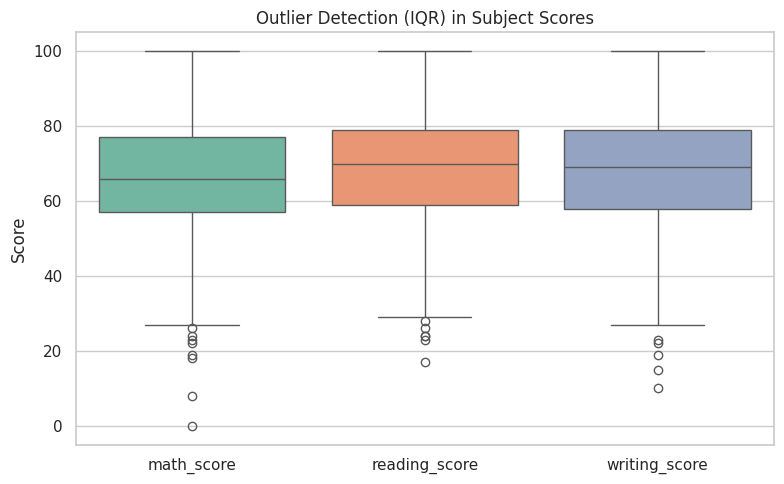

In [29]:
# Visual: before vs after (box plots) is the same here, so show outliers themselves
plt.figure(figsize=(8, 5))
sns.boxplot(data=df[score_cols], palette="Set2")
plt.title("Outlier Detection (IQR) in Subject Scores"); plt.ylabel("Score")
save_and_show("00_outlier_detection")

### 4.5 Before / after comparison

In [30]:
# 4.5 Before / after comparison
section("STEP 4.5: BEFORE vs AFTER CLEANING")
comparison = pd.DataFrame({
    "Before cleaning": [df_raw.shape[0], df_raw.shape[1], int(df_raw.isna().sum().sum()),
                        int(df_raw.duplicated().sum()), ", ".join(df_raw.columns[:3]) + ", ..."],
    "After cleaning": [df.shape[0], df.shape[1], int(df.isna().sum().sum()),
                       int(df.duplicated().sum()), ", ".join(df.columns[:3]) + ", ..."],
}, index=["Rows", "Columns (after = +is_outlier flag)", "Missing values", "Duplicate rows", "Column names"])
print(comparison)
stats_cmp = pd.concat([df_raw.rename(columns=lambda x: x.replace(" ", "_"))[score_cols].mean(),
                       df[score_cols].mean()], axis=1, keys=["mean_before", "mean_after"]).round(3)
print("\nScore means before / after:"); print(stats_cmp)
comparison.to_csv(OUTPUT_DIR / "before_after_cleaning.csv")
df.to_csv(OUTPUT_DIR / "cleaned_students.csv", index=False)
print("\nSaved cleaned data -> outputs/cleaned_students.csv")


STEP 4.5: BEFORE vs AFTER CLEANING
                                                                      Before cleaning                                     After cleaning
Rows                                                                             1000                                               1000
Columns (after = +is_outlier flag)                                                  8                                                  9
Missing values                                                                      0                                                  0
Duplicate rows                                                                      0                                                  0
Column names                        gender, race/ethnicity, parental level of educ...  gender, race_ethnicity, parental_level_of_educ...

Score means before / after:
               mean_before  mean_after
math_score          66.089      66.089
reading_score       69.169      69.

## Step 5: Exploratory Data Analysis (EDA)

Descriptive statistics, numerical and categorical analysis, group comparisons, correlations, and at least five observations (computed from the data).

In [31]:
section("STEP 5: EXPLORATORY DATA ANALYSIS")
df["average_score"] = df[score_cols].mean(axis=1)       # needed for EDA (also used in Step 8)


STEP 5: EXPLORATORY DATA ANALYSIS


### 5.1 descriptive statistics

In [32]:
# 5.1 descriptive statistics
print("Descriptive statistics:")
print(df[score_cols + ["average_score"]].agg(["mean", "median", "std", "min", "max", "skew"]).T.round(2))

Descriptive statistics:
                mean  median    std   min    max  skew
math_score     66.09   66.00  15.16   0.0  100.0 -0.28
reading_score  69.17   70.00  14.60  17.0  100.0 -0.26
writing_score  68.05   69.00  15.20  10.0  100.0 -0.29
average_score  67.77   68.33  14.26   9.0  100.0 -0.30


### 5.2 numerical & categorical variables

In [33]:
# 5.2 numerical & categorical variables
for c in cat_cols:
    vc = df[c].value_counts()
    print(f"\n{c}:\n", pd.DataFrame({"count": vc, "percent": (vc / len(df) * 100).round(1)}))


gender:
         count  percent
gender                
female    518     51.8
male      482     48.2

race_ethnicity:
                 count  percent
race_ethnicity                
group c           319     31.9
group d           262     26.2
group b           190     19.0
group e           140     14.0
group a            89      8.9

parental_level_of_education:
                              count  percent
parental_level_of_education                
some college                   226     22.6
associate's degree             222     22.2
high school                    196     19.6
some high school               179     17.9
bachelor's degree              118     11.8
master's degree                 59      5.9

lunch:
               count  percent
lunch                       
standard        645     64.5
free/reduced    355     35.5

test_preparation_course:
                          count  percent
test_preparation_course                
none                       642     64.2
complete

### 5.3 patterns & relationships

In [34]:
# 5.3 patterns & relationships
print("\nAverage scores by gender:");              print(df.groupby("gender")[score_cols].mean().round(2))
print("\nAverage scores by test preparation:");    print(df.groupby("test_preparation_course")[score_cols].mean().round(2))
print("\nAverage scores by lunch type:");          print(df.groupby("lunch")[score_cols].mean().round(2))
print("\nAverage scores by race/ethnicity:");      print(df.groupby("race_ethnicity")[score_cols].mean().round(2))
edu_order = ["some high school", "high school", "some college", "associate's degree",
             "bachelor's degree", "master's degree"]
print("\nAverage scores by parental education:")
print(df.groupby("parental_level_of_education")[score_cols].mean().reindex(edu_order).round(2))


Average scores by gender:
        math_score  reading_score  writing_score
gender                                          
female       63.63          72.61          72.47
male         68.73          65.47          63.31

Average scores by test preparation:
                         math_score  reading_score  writing_score
test_preparation_course                                          
completed                     69.70          73.89          74.42
none                          64.08          66.53          64.50

Average scores by lunch type:
              math_score  reading_score  writing_score
lunch                                                 
free/reduced       58.92          64.65          63.02
standard           70.03          71.65          70.82

Average scores by race/ethnicity:
                math_score  reading_score  writing_score
race_ethnicity                                          
group a              61.63          64.67          62.67
group b            

### 5.4 correlations

In [35]:
# 5.4 correlations
corr = df[score_cols].corr()
print("\nCorrelation matrix:"); print(corr.round(3))


Correlation matrix:
               math_score  reading_score  writing_score
math_score          1.000          0.818          0.803
reading_score       0.818          1.000          0.955
writing_score       0.803          0.955          1.000


### 5.5 observations

In [36]:
# 5.5 observations (numbers are computed from the data)
g = df.groupby("gender")[score_cols].mean()
t = df.groupby("test_preparation_course")[score_cols].mean()
l = df.groupby("lunch")[score_cols].mean()
e = df.groupby("parental_level_of_education")["average_score"].mean()
r = df.groupby("race_ethnicity")["average_score"].mean()
pass_rate = (df[score_cols] >= 40).all(axis=1).mean() * 100
print("\n" + "-" * 80 + "\nKEY OBSERVATIONS\n" + "-" * 80)
observations = [
    f"Reading and writing are strongly correlated (r = {corr.loc['reading_score','writing_score']:.2f}); "
    f"math is also strongly related to both (r = {corr.loc['math_score','reading_score']:.2f} with reading, "
    f"{corr.loc['math_score','writing_score']:.2f} with writing).",
    f"Gender gap is subject-specific: males score higher in math ({g.loc['male','math_score']:.1f} vs "
    f"{g.loc['female','math_score']:.1f}) while females lead in reading ({g.loc['female','reading_score']:.1f} vs "
    f"{g.loc['male','reading_score']:.1f}) and writing ({g.loc['female','writing_score']:.1f} vs "
    f"{g.loc['male','writing_score']:.1f}).",
    f"Completing the test-preparation course is associated with higher scores in every subject; the average score is "
    f"{df[df.test_preparation_course=='completed'].average_score.mean():.1f} vs "
    f"{df[df.test_preparation_course=='none'].average_score.mean():.1f} for students with no preparation.",
    f"Lunch type shows the largest gap: standard-lunch students average {df[df.lunch=='standard'].average_score.mean():.1f} "
    f"vs {df[df.lunch=='free/reduced'].average_score.mean():.1f} for free/reduced lunch "
    f"(lunch is often used as a proxy for socio-economic status).",
    f"Parental education shows a gradient: students whose parents hold a master's degree average {e['master\'s degree']:.1f}, "
    f"whereas those whose parents attended only some high school average {e['some high school']:.1f}.",
    f"Race/ethnicity groups differ: group E has the highest average ({r.max():.1f}) and group A the lowest ({r.min():.1f}); "
    f"these are anonymised groups, so this should not be read causally.",
    f"Math has the lowest mean ({df.math_score.mean():.1f}) and the widest spread of low scores; "
    f"{int(outlier_report.loc[0,'n_outliers'])} math outliers, all at the low end (minimum = {df.math_score.min()}).",
    f"Overall, {pass_rate:.1f}% of students scored at least 40 in all three subjects.",
]
for i, o in enumerate(observations, 1):
    print(f"{i}. {o}")


--------------------------------------------------------------------------------
KEY OBSERVATIONS
--------------------------------------------------------------------------------
1. Reading and writing are strongly correlated (r = 0.95); math is also strongly related to both (r = 0.82 with reading, 0.80 with writing).
2. Gender gap is subject-specific: males score higher in math (68.7 vs 63.6) while females lead in reading (72.6 vs 65.5) and writing (72.5 vs 63.3).
3. Completing the test-preparation course is associated with higher scores in every subject; the average score is 72.7 vs 65.0 for students with no preparation.
4. Lunch type shows the largest gap: standard-lunch students average 70.8 vs 62.2 for free/reduced lunch (lunch is often used as a proxy for socio-economic status).
5. Parental education shows a gradient: students whose parents hold a master's degree average 73.6, whereas those whose parents attended only some high school average 65.1.
6. Race/ethnicity groups diffe

## Step 6: Data Visualization Using Matplotlib

Static charts with Matplotlib (and Seaborn for styling): histogram, bar chart, line chart, scatter plot, box plot and correlation heatmap. Every chart is also saved to `outputs/charts/`.

In [37]:
section("STEP 6: MATPLOTLIB VISUALISATIONS")


STEP 6: MATPLOTLIB VISUALISATIONS


### 1. Histogram

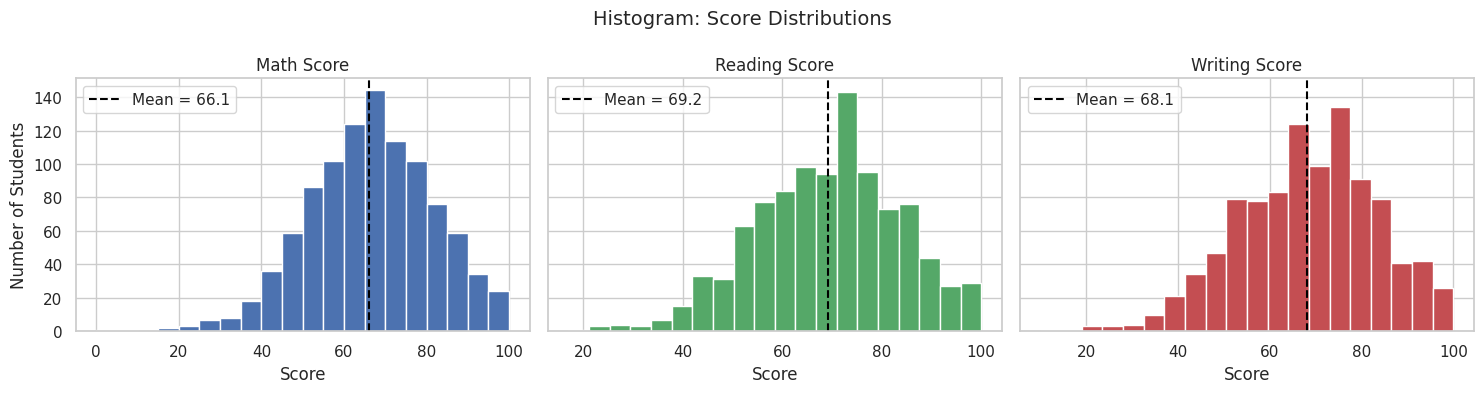

In [38]:
# 1. Histogram
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, c, col in zip(axes, score_cols, ["#4C72B0", "#55A868", "#C44E52"]):
    ax.hist(df[c], bins=20, color=col, edgecolor="white")
    ax.axvline(df[c].mean(), color="black", linestyle="--", label=f"Mean = {df[c].mean():.1f}")
    ax.set_title(c.replace("_", " ").title()); ax.set_xlabel("Score"); ax.legend()
axes[0].set_ylabel("Number of Students")
fig.suptitle("Histogram: Score Distributions", fontsize=14)
save_and_show("01_histograms")

### 2. Bar chart

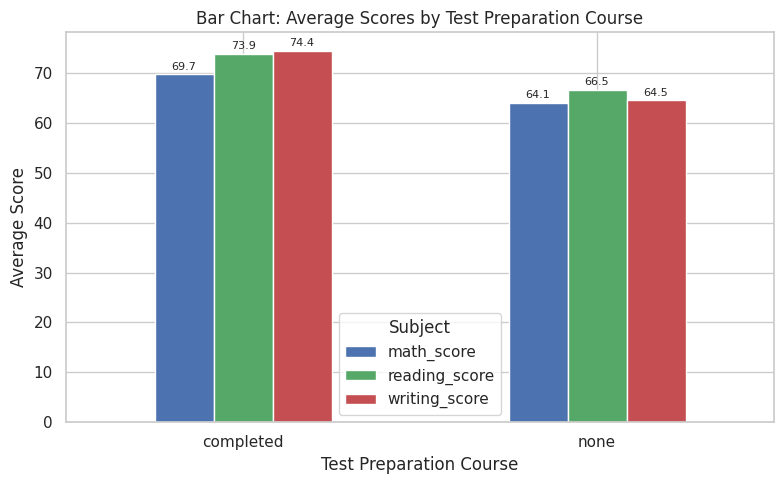

In [39]:
# 2. Bar chart
means = df.groupby("test_preparation_course")[score_cols].mean()
ax = means.plot(kind="bar", figsize=(8, 5), rot=0, color=["#4C72B0", "#55A868", "#C44E52"], edgecolor="white")
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.1f", padding=2, fontsize=8)
plt.title("Bar Chart: Average Scores by Test Preparation Course")
plt.xlabel("Test Preparation Course"); plt.ylabel("Average Score"); plt.legend(title="Subject")
save_and_show("02_bar_chart_test_prep")

### 3. Line chart

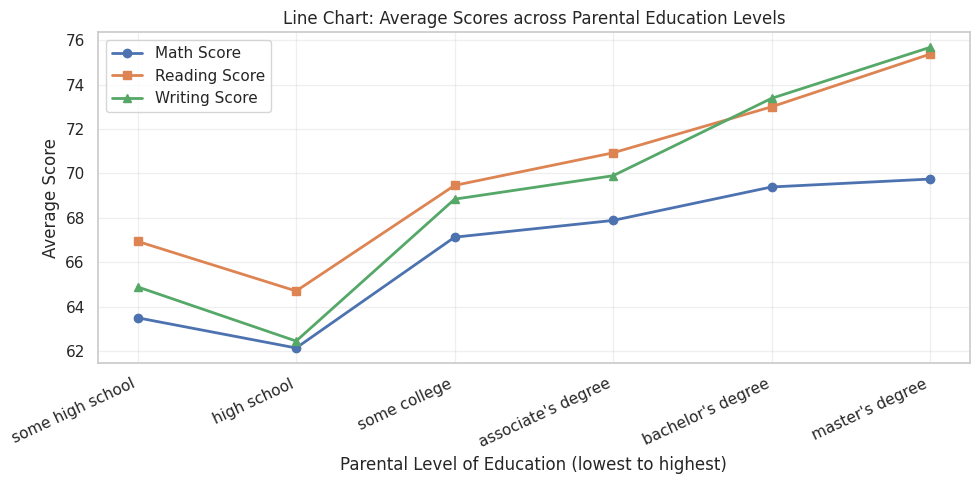

In [40]:
# 3. Line chart (no date column exists -> use ordered parental education levels)
line_data = df.groupby("parental_level_of_education")[score_cols].mean().reindex(edu_order)
plt.figure(figsize=(10, 5))
for c, m in zip(score_cols, ["o", "s", "^"]):
    plt.plot(line_data.index, line_data[c], marker=m, linewidth=2, label=c.replace("_", " ").title())
plt.title("Line Chart: Average Scores across Parental Education Levels")
plt.xlabel("Parental Level of Education (lowest to highest)"); plt.ylabel("Average Score")
plt.xticks(rotation=25, ha="right"); plt.legend(); plt.grid(alpha=0.3)
save_and_show("03_line_chart_parental_education")

### 4. Scatter plot

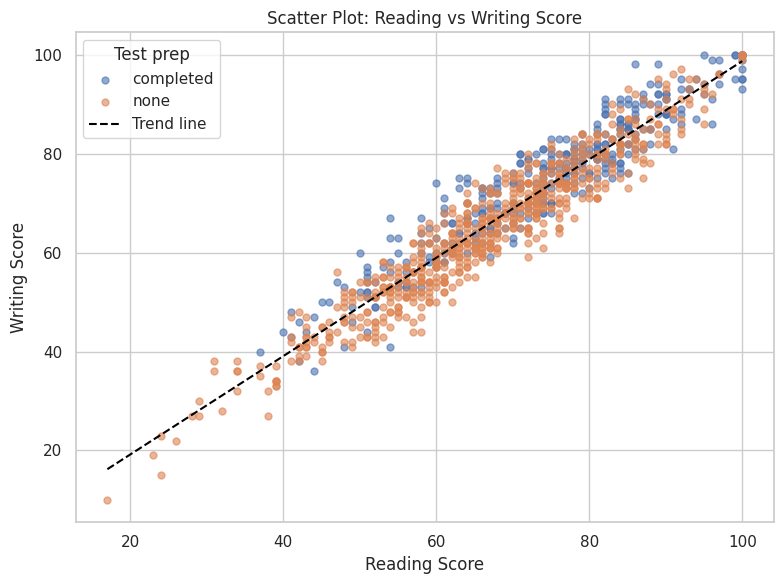

In [41]:
# 4. Scatter plot
plt.figure(figsize=(8, 6))
for name, grp in df.groupby("test_preparation_course"):
    plt.scatter(grp["reading_score"], grp["writing_score"], alpha=0.6, label=name, s=25)
m_, b_ = np.polyfit(df["reading_score"], df["writing_score"], 1)      # NumPy regression line
xs = np.linspace(df["reading_score"].min(), 100, 100)
plt.plot(xs, m_ * xs + b_, color="black", linestyle="--", label="Trend line")
plt.title("Scatter Plot: Reading vs Writing Score")
plt.xlabel("Reading Score"); plt.ylabel("Writing Score"); plt.legend(title="Test prep")
save_and_show("04_scatter_reading_writing")

### 5. Box plot

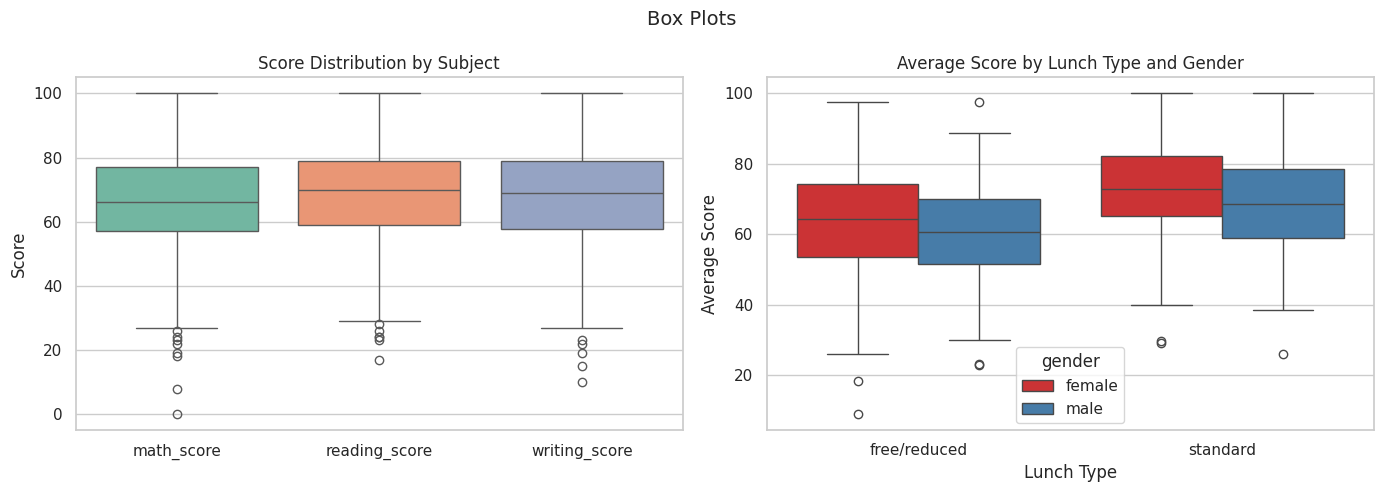

In [42]:
# 5. Box plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df[score_cols], palette="Set2", ax=axes[0])
axes[0].set_title("Score Distribution by Subject"); axes[0].set_ylabel("Score")
sns.boxplot(data=df, x="lunch", y="average_score", hue="gender", palette="Set1", ax=axes[1])
axes[1].set_title("Average Score by Lunch Type and Gender")
axes[1].set_xlabel("Lunch Type"); axes[1].set_ylabel("Average Score")
fig.suptitle("Box Plots", fontsize=14)
save_and_show("05_box_plots")

### 6. Correlation heatmap

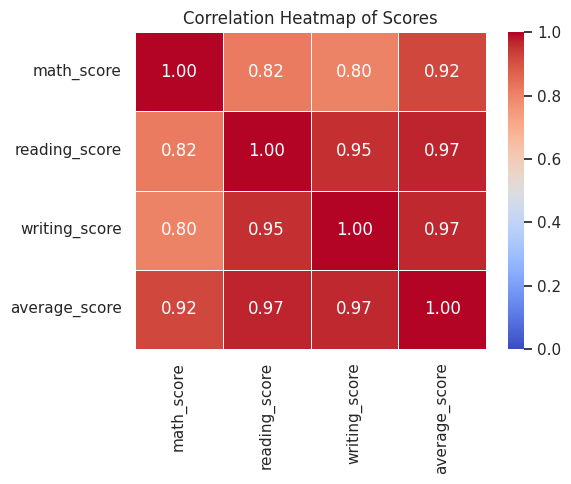

In [43]:
# 6. Correlation heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(df[score_cols + ["average_score"]].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=0, vmax=1, linewidths=0.5)
plt.title("Correlation Heatmap of Scores")
save_and_show("06_correlation_heatmap")

## Step 7: Interactive Visualization Using Plotly

Interactive Plotly charts with titles, axis labels, legends and hover information. Hover over points/bars, click legend items to hide/show groups, and drag to zoom.

In [44]:
section("STEP 7: PLOTLY INTERACTIVE VISUALISATIONS")
labels = {"math_score": "Math Score", "reading_score": "Reading Score", "writing_score": "Writing Score",
          "average_score": "Average Score", "gender": "Gender", "test_preparation_course": "Test Preparation",
          "lunch": "Lunch Type", "parental_level_of_education": "Parental Education",
          "race_ethnicity": "Race/Ethnicity"}
plot_df = df.copy()
for c in cat_cols:
    plot_df[c] = plot_df[c].astype(str)


STEP 7: PLOTLY INTERACTIVE VISUALISATIONS


### 1. Interactive histogram

In [45]:
# 1. Interactive histogram
fig = px.histogram(plot_df, x="math_score", color="gender", nbins=25, barmode="overlay", opacity=0.7,
                   marginal="box", hover_data=["lunch", "test_preparation_course"], labels=labels,
                   title="Interactive Histogram: Math Score Distribution by Gender")
fig.update_layout(xaxis_title="Math Score", yaxis_title="Number of Students", legend_title="Gender")
save_plotly(fig, "07_interactive_histogram")

### 2. Interactive scatter plot

In [46]:
# 2. Interactive scatter plot
fig = px.scatter(plot_df, x="reading_score", y="writing_score", color="test_preparation_course",
                 size="math_score", size_max=14, opacity=0.7,
                 hover_data=["gender", "lunch", "parental_level_of_education", "math_score"], labels=labels,
                 title="Interactive Scatter: Reading vs Writing (bubble size = Math Score)")
fig.update_layout(legend_title="Test Preparation")
save_plotly(fig, "08_interactive_scatter")

### 3. Interactive bar chart

In [47]:
# 3. Interactive bar chart
bar_df = (plot_df.groupby(["parental_level_of_education", "lunch"], as_index=False)["average_score"].mean()
          .round(2))
fig = px.bar(bar_df, x="parental_level_of_education", y="average_score", color="lunch", barmode="group",
             text="average_score", category_orders={"parental_level_of_education": edu_order}, labels=labels,
             title="Interactive Bar Chart: Average Score by Parental Education and Lunch Type")
fig.update_layout(xaxis_title="Parental Level of Education", yaxis_title="Average Score",
                  legend_title="Lunch Type")
fig.update_traces(textposition="outside")
save_plotly(fig, "09_interactive_bar")

### Bonus

In [48]:
# Bonus: interactive correlation heatmap
fig = px.imshow(df[score_cols].corr().round(2), text_auto=True, color_continuous_scale="RdBu_r",
                zmin=0, zmax=1, title="Interactive Correlation Heatmap")
save_plotly(fig, "10_interactive_heatmap")

print("""
INTERPRETATION OF INTERACTIVE PLOTS
- Histogram : math scores are roughly bell-shaped around 66. The female distribution sits slightly left of
              the male one, and the box margin shows the low-score outliers. Hover over a bar for counts;
              click a legend item to isolate one gender.
- Scatter   : reading and writing form a tight upward band (very strong linear relationship). Students with
              the test-prep course 'completed' cluster toward the upper-right. Hover to see each student's
              background; bigger bubbles are higher math scorers who tend to also sit in the upper band.
- Bar chart : in every parental-education level, standard-lunch students outscore free/reduced-lunch
              students, and averages are generally higher for higher parental education - both effects appear together.
""")


INTERPRETATION OF INTERACTIVE PLOTS
- Histogram : math scores are roughly bell-shaped around 66. The female distribution sits slightly left of
              the male one, and the box margin shows the low-score outliers. Hover over a bar for counts;
              click a legend item to isolate one gender.
- Scatter   : reading and writing form a tight upward band (very strong linear relationship). Students with
              the test-prep course 'completed' cluster toward the upper-right. Hover to see each student's
              background; bigger bubbles are higher math scorers who tend to also sit in the upper band.
- Bar chart : in every parental-education level, standard-lunch students outscore free/reduced-lunch
              students, and averages are generally higher for higher parental education - both effects appear together.



## Step 8: Feature Engineering

Create new features, encode categorical variables and scale numerical variables, then save the engineered dataset.

In [49]:
section("STEP 8: FEATURE ENGINEERING")
fe = df.copy()
for c in cat_cols:
    fe[c] = fe[c].astype(str)


STEP 8: FEATURE ENGINEERING


### 8.1 New meaningful features

In [50]:
# 8.1 New meaningful features
fe["total_score"] = fe[score_cols].sum(axis=1)
fe["average_score"] = fe[score_cols].mean(axis=1).round(2)
fe["writing_reading_gap"] = fe["writing_score"] - fe["reading_score"]
fe["math_vs_verbal_gap"] = fe["math_score"] - fe[["reading_score", "writing_score"]].mean(axis=1)
fe["subjects_above_60"] = (fe[score_cols] >= 60).sum(axis=1)
fe["score_std"] = fe[score_cols].std(axis=1).round(2)                  # consistency across subjects
fe["strongest_subject"] = fe[score_cols].idxmax(axis=1).str.replace("_score", "")
fe["weakest_subject"] = fe[score_cols].idxmin(axis=1).str.replace("_score", "")
fe["performance_grade"] = pd.cut(fe["average_score"], bins=[-1, 39.99, 59.99, 79.99, 100],
                                 labels=["Needs Support", "Average", "Good", "Excellent"])
fe["pass_all_subjects"] = (fe[score_cols] >= 40).all(axis=1).astype(int)
fe["high_achiever"] = (fe["average_score"] >= fe["average_score"].quantile(0.75)).astype(int)

### 8.2 Date/time features

In [51]:
# 8.2 Date/time features
print("Date/time columns available: NONE - the dataset has no date or time column, so no datetime")
print("features (year, month, weekday, ...) can be extracted. Example of what would be done:")
print("    df['date'] = pd.to_datetime(df['date']); df['month'] = df['date'].dt.month")

Date/time columns available: NONE - the dataset has no date or time column, so no datetime
features (year, month, weekday, ...) can be extracted. Example of what would be done:
    df['date'] = pd.to_datetime(df['date']); df['month'] = df['date'].dt.month


### 8.3 Categorical encoding

In [52]:
# 8.3 Categorical encoding
# (a) Binary encoding
fe["gender_male"] = (fe["gender"] == "male").astype(int)
fe["lunch_standard"] = (fe["lunch"] == "standard").astype(int)
fe["test_prep_completed"] = (fe["test_preparation_course"] == "completed").astype(int)
# (b) Ordinal encoding: parental education has a natural order
edu_map = {k: i for i, k in enumerate(edu_order)}
fe["parent_edu_level"] = fe["parental_level_of_education"].map(edu_map)
# (c) One-hot encoding: race/ethnicity and strongest subject are nominal
fe = pd.get_dummies(fe, columns=["race_ethnicity", "strongest_subject"], dtype=int)

### 8.4 Numerical scaling

In [53]:
# 8.4 Numerical scaling (implemented with NumPy / Pandas formulas)
scale_cols = score_cols + ["total_score", "average_score", "writing_reading_gap", "math_vs_verbal_gap"]
for c in scale_cols:
    fe[f"{c}_std"] = (fe[c] - fe[c].mean()) / fe[c].std(ddof=0)                 # Z-score (StandardScaler)
    fe[f"{c}_minmax"] = (fe[c] - fe[c].min()) / (fe[c].max() - fe[c].min())     # Min-Max scaling (0-1)

print("\nEngineered dataset shape:", fe.shape)
print("\nNew engineered features (sample):")
print(fe[["total_score", "average_score", "writing_reading_gap", "math_vs_verbal_gap", "subjects_above_60",
          "score_std", "weakest_subject", "performance_grade", "pass_all_subjects", "high_achiever"]].head(8))
print("\nPerformance grade distribution:"); print(fe["performance_grade"].value_counts().sort_index())
print("\nScaled features check (mean ~ 0 and std ~ 1 for z-score; min 0 / max 1 for min-max):")
print(fe[[f"{c}_std" for c in score_cols]].agg(["mean", "std"]).round(3))
print(fe[[f"{c}_minmax" for c in score_cols]].agg(["min", "max"]))


Engineered dataset shape: (1000, 44)

New engineered features (sample):
   total_score  average_score  writing_reading_gap  math_vs_verbal_gap  subjects_above_60  score_std weakest_subject performance_grade  \
0          218          72.67                    2                -1.0                  3       1.15            math              Good   
1          247          82.33                   -2               -20.0                  3      11.59            math         Excellent   
2          278          92.67                   -2                -4.0                  3       2.52            math         Excellent   
3          148          49.33                  -13                -3.5                  0       6.81         writing           Average   
4          229          76.33                   -3                -0.5                  3       1.53         writing              Good   
5          232          77.33                   -5                -9.5                  3       6.0

### A feature-engineering visual

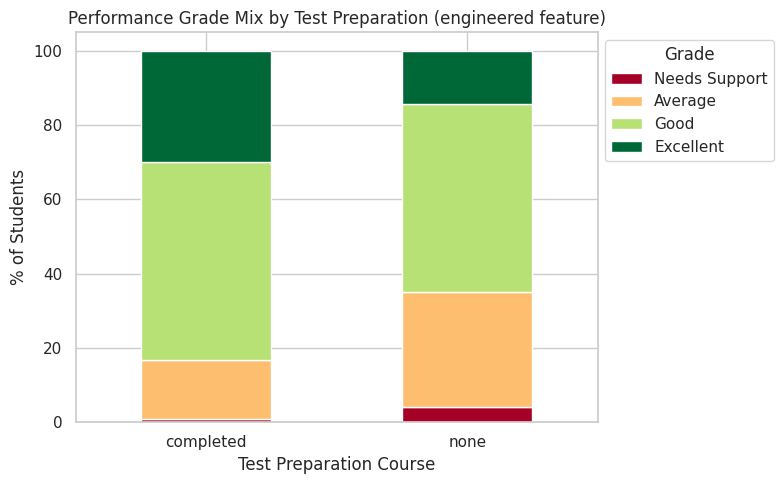

In [54]:
# A feature-engineering visual: grades by test prep
pd.crosstab(df["test_preparation_course"], fe["performance_grade"], normalize="index").mul(100).plot(
    kind="bar", stacked=True, rot=0, colormap="RdYlGn", figsize=(8, 5))
plt.title("Performance Grade Mix by Test Preparation (engineered feature)")
plt.ylabel("% of Students"); plt.xlabel("Test Preparation Course"); plt.legend(title="Grade", bbox_to_anchor=(1, 1))
save_and_show("11_performance_grade_by_test_prep")

### Correlation of engineered numeric features with the average score

In [55]:
# Correlation of engineered numeric features with the average score
num_feats = ["gender_male", "lunch_standard", "test_prep_completed", "parent_edu_level", "average_score"]
print("\nCorrelation of encoded background features with average_score:")
print(fe[num_feats].corr()["average_score"].drop("average_score").round(3).sort_values(ascending=False))

fe.to_csv(OUTPUT_DIR / "feature_engineered_students.csv", index=False)
print("\nSaved -> outputs/feature_engineered_students.csv")

print("""
PURPOSE AND IMPORTANCE OF THE ENGINEERED FEATURES
- total_score / average_score : one overall performance measure, usable as a regression target.
- writing_reading_gap, math_vs_verbal_gap : show a student's subject balance (e.g. strong in math, weak in language).
- subjects_above_60, pass_all_subjects : simple achievement indicators useful for classification problems.
- score_std : how consistent a student is across subjects.
- strongest_subject / weakest_subject : categorical descriptors of student profile.
- performance_grade, high_achiever : binned/binary targets for classification and easy reporting.
- Binary / ordinal / one-hot encoding : ML algorithms need numbers; ordinal encoding keeps the natural order
  of parental education, while one-hot encoding avoids imposing a false order on race/ethnicity groups.
- Z-score and Min-Max scaling : put features on comparable scales, needed by distance- and gradient-based
  models (KNN, SVM, logistic/linear regression, neural networks).
""")


Correlation of encoded background features with average_score:
lunch_standard         0.290
test_prep_completed    0.257
parent_edu_level       0.206
gender_male           -0.131
Name: average_score, dtype: float64

Saved -> outputs/feature_engineered_students.csv

PURPOSE AND IMPORTANCE OF THE ENGINEERED FEATURES
- total_score / average_score : one overall performance measure, usable as a regression target.
- writing_reading_gap, math_vs_verbal_gap : show a student's subject balance (e.g. strong in math, weak in language).
- subjects_above_60, pass_all_subjects : simple achievement indicators useful for classification problems.
- score_std : how consistent a student is across subjects.
- strongest_subject / weakest_subject : categorical descriptors of student profile.
- performance_grade, high_achiever : binned/binary targets for classification and easy reporting.
- Binary / ordinal / one-hot encoding : ML algorithms need numbers; ordinal encoding keeps the natural order
  of parenta

## Step 9: Analysis and Conclusion

Summary of findings, patterns, recommendations and limitations.

In [56]:
section("STEP 9: ANALYSIS AND CONCLUSION")
gap_prep = fe.loc[fe.test_prep_completed == 1, "average_score"].mean() - fe.loc[fe.test_prep_completed == 0, "average_score"].mean()
gap_lunch = fe.loc[fe.lunch_standard == 1, "average_score"].mean() - fe.loc[fe.lunch_standard == 0, "average_score"].mean()
share_prep = (df["test_preparation_course"] == "completed").mean() * 100
share_free = (df["lunch"] == "free/reduced").mean() * 100

print(f"""
SUMMARY OF MAJOR FINDINGS
- The dataset is clean: 1000 rows, no missing values, no duplicates; {int(df['is_outlier'].sum())} students are low-score outliers (kept).
- Mean scores: math {df.math_score.mean():.1f}, reading {df.reading_score.mean():.1f}, writing {df.writing_score.mean():.1f}.
- Reading and writing are almost interchangeable (r = {corr.loc['reading_score','writing_score']:.2f}); math is somewhat more independent.
- Test preparation is linked to +{gap_prep:.1f} average points; standard lunch is linked to +{gap_lunch:.1f} points.
- Parental education is positively associated with scores (higher parental education generally means higher scores).
- Males lead in math; females lead in reading and writing.

IMPORTANT PATTERNS AND RELATIONSHIPS
- Strong positive correlations among all three subjects: a student good in one subject tends to be good in the others.
- Socio-economic proxy (lunch) and test preparation show the biggest group differences.
- Only {share_prep:.1f}% of students completed the test-preparation course, so there is a large untapped group.

CONCLUSIONS / RECOMMENDATIONS
1. Encourage and subsidise test-preparation courses: only {share_prep:.1f}% completed them, yet they show consistently higher scores in all subjects.
2. Provide targeted support (tutoring, nutrition / financial aid) for students on free/reduced lunch ({share_free:.1f}% of students), the group with the lowest averages.
3. Use a student's math-vs-verbal gap to personalise help: boys may need reading/writing support, girls may need math support.
4. Use the engineered 'Needs Support' grade and low-score outlier flag as an early-warning list for intervention.
5. Engage parents with lower education levels (e.g. through study-guidance workshops) because parental education tracks student scores.

LIMITATIONS
- Only 1000 records, from a single (likely synthetic/fictional) source; results may not generalise to other schools or countries.
- No time/date column, so no trend over time or change in performance can be studied.
- Race/ethnicity groups are anonymised and socio-economic status is only approximated through lunch type.
- Important factors are missing: study hours, attendance, teacher quality, prior grades, school type.
- Observed relationships are correlations, NOT causal effects; e.g. test prep may attract more motivated students.
- Scores are bounded to 0-100 and the engineered thresholds (40 / 60 / 80) are illustrative choices.
""")

section("DONE - outputs saved in the 'outputs' folder")
for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file():
        print(" ", p.relative_to(BASE_DIR))


STEP 9: ANALYSIS AND CONCLUSION

SUMMARY OF MAJOR FINDINGS
- The dataset is clean: 1000 rows, no missing values, no duplicates; 12 students are low-score outliers (kept).
- Mean scores: math 66.1, reading 69.2, writing 68.1.
- Reading and writing are almost interchangeable (r = 0.95); math is somewhat more independent.
- Test preparation is linked to +7.6 average points; standard lunch is linked to +8.6 points.
- Parental education is positively associated with scores (higher parental education generally means higher scores).
- Males lead in math; females lead in reading and writing.

IMPORTANT PATTERNS AND RELATIONSHIPS
- Strong positive correlations among all three subjects: a student good in one subject tends to be good in the others.
- Socio-economic proxy (lunch) and test preparation show the biggest group differences.
- Only 35.8% of students completed the test-preparation course, so there is a large untapped group.

CONCLUSIONS / RECOMMENDATIONS
1. Encourage and subsidise test-